# Ticha HTR — TrOCR fine-tuning

This notebook fine-tunes `microsoft/trocr-base-handwritten` on `maclenn77/ticha-htr-lines`, using its existing `train`, `validation`, and `test` splits.

It runs in **Google Colab** or on the **GCP VM** (`ticha-l4`, NVIDIA L4):

- **Colab:** choose **Runtime → Change runtime type → T4 GPU** (or another available GPU). Outputs go to Google Drive.
- **VM:** open it through the SSH tunnel and pick the **Python (ticha-trocr)** kernel (see `ENVIRONMENT.md`). Outputs go to `~/ticha-runs/` on the VM, or to `$TICHA_OUTPUT_DIR` if set.

**Research note:** This uses TrOCR because the dataset provides image/text line pairs directly. Your project report names Kraken as the main framework, so treat this as the TrOCR experiment/comparison rather than the Kraken run.

In [13]:
import sys
IN_COLAB = 'google.colab' in sys.modules

# The VM's kernel already has these installed; Colab needs them on every new runtime.
if IN_COLAB:
    %pip -q install "transformers==4.46.3" "datasets>=2.19,<4" "accelerate>=0.26" "jiwer>=3.0"

In [14]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

import os
# The dataloader workers fork after the tokenizer has run; this avoids a warning per worker.
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
import numpy as np
import torch
from datasets import load_dataset
from IPython.display import display

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

ds = load_dataset('maclenn77/ticha-htr-lines', 'original')
print(ds)
for split_name, split_data in ds.items():
    print(f'{split_name}: {len(split_data):,} rows; columns={split_data.column_names}')

PyTorch: 2.9.1+cu129
CUDA available: True
GPU: NVIDIA L4
DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url'],
        num_rows: 5786
    })
    validation: Dataset({
        features: ['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url'],
        num_rows: 819
    })
    test: Dataset({
        features: ['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url'],
        num_rows: 1066
    })
})
train: 5,786 rows; columns=['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url']
validation: 819 rows; columns=['id', 'image', 'text', 'doc_id', 'page', 'line', 'language', 'source', 'year', 'town', 'doc_type', 'document_url']
test: 1,066 rows; columns=['id', 'image', 'text', 'doc_id', 'page', 'line', 

In [15]:
# Audit the existing split by document. Shared doc_id values would make evaluation unreliable.
required_columns = {'image', 'text', 'doc_id'}
for split_name, split_data in ds.items():
    missing = required_columns - set(split_data.column_names)
    if missing:
        raise ValueError(f'{split_name} is missing required columns: {missing}')

doc_sets = {
    name: {str(x) for x in data['doc_id'] if x is not None}
    for name, data in ds.items()
}
overlaps = {
    'train-validation': doc_sets['train'] & doc_sets['validation'],
    'train-test': doc_sets['train'] & doc_sets['test'],
    'validation-test': doc_sets['validation'] & doc_sets['test'],
}
for pair, shared_docs in overlaps.items():
    print(f'{pair} shared document IDs: {len(shared_docs)}')
    if shared_docs:
        print('Examples:', list(sorted(shared_docs))[:10])

for split_name, split_data in ds.items():
    missing_doc_ids = sum(x is None for x in split_data['doc_id'])
    print(f'{split_name}: rows without doc_id = {missing_doc_ids}')

if any(overlaps.values()):
    print('WARNING: document leakage detected. Do not train until document-level splits are fixed.')
else:
    print('Good: no shared non-null document IDs were found across splits.')


train-validation shared document IDs: 0
train-test shared document IDs: 0
validation-test shared document IDs: 0
train: rows without doc_id = 0
validation: rows without doc_id = 0
test: rows without doc_id = 0
Good: no shared non-null document IDs were found across splits.


Sample text: 'exChij beo de o'
Document: An740 | language: Zapotec | source: auto


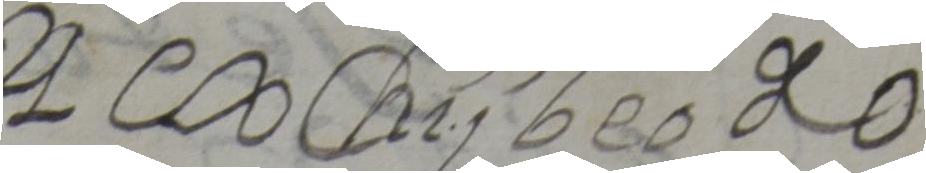

train: empty texts=0, p50=49 chars, p95=67 chars, max=113
validation: empty texts=0, p50=50 chars, p95=67 chars, max=164
test: empty texts=0, p50=48 chars, p95=62 chars, max=82


In [16]:
# Inspect one sample and the transcription-length distribution.
sample = ds['train'][0]
print('Sample text:', repr(sample['text']))
print('Document:', sample['doc_id'], '| language:', sample.get('language'), '| source:', sample.get('source'))
display(sample['image'].convert('RGB'))

for split_name, split_data in ds.items():
    lengths = np.array([len(str(t or '').strip()) for t in split_data['text']])
    print(f"{split_name}: empty texts={(lengths == 0).sum()}, p50={np.percentile(lengths, 50):.0f} chars, p95={np.percentile(lengths, 95):.0f} chars, max={lengths.max()}")


## Clean transcriber notes

The transcriptions mark expansions, glosses and damage with `[]` and `()`. This cell turns them into diplomatic text (what is written on the page) and drops lines whose image and text don't match. Uncertain readings such as `(Santigo?)` are kept as text in train and dropped from validation and test, so the reported CER is on confident transcriptions only (state this in the report). It changes the text only for this experiment: the Hub dataset stays as published, and the original text is kept in `text_raw`.

Run it before the baseline so the baseline, the fine-tuned model and later experiments are all evaluated on the same cleaned test set.

In [17]:
# Transcriber notes: make the text match what is written on the page (diplomatic transcription).
# The transcriptions use [] and () for three things:
#   - abbreviation expansions, p[es]os, to[mine]s, Dom(ing)o: the bracketed letters are not written,
#     so they are deleted (p[es]os -> pos)
#   - glosses, [=Juan]: not on the page, deleted
#   - damage, illegible text and editorial notes, [cortado], [roto], [xxx], [...], [?], [n?],
#     [margin note], (?), (word?): the image has ink the text doesn't cover, so the whole line is dropped
#   - uncertain readings, (Santigo?): the letters are on the page but the transcriber wasn't sure.
#     In train they are kept as text (Santigo); in validation and test the line is dropped, so
#     evaluation uses only confident transcriptions.
# Lines with unbalanced or nested brackets are dropped too.
import re

BRACKET_RE = re.compile(r'\[([^\[\]]*)\]|\(([^()]*)\)')
NOTE_RE = re.compile(
    r'[?…]|^\.+$|\.\.|\s|,|^x+$|^word$'                   # uncertain, illegible, or a note with spaces
    r'|cortado|roto|torn|mancha|borrado|firmas|ilegible',  # damage and editorial notes
    re.IGNORECASE)
DROP_HASH = True  # '#' marks illegible characters in some documents
KEEP_GUESSES_IN_TRAIN = True
GUESS_RE = re.compile(r'\((?!word\?)([^()?]*[^\W\d_][^()?]*)\?+\)')  # (letters?) but not (word?)


def clean_text(text, keep_guesses=False):
    """Return the diplomatic text, or None when the line should be dropped."""
    text = str(text or '')
    if keep_guesses:
        text = GUESS_RE.sub(lambda m: m.group(1), text)
    notes = [square or round for square, round in BRACKET_RE.findall(text)]
    if any(NOTE_RE.search(note.strip()) for note in notes if not note.strip().startswith('=')):
        return None
    text = BRACKET_RE.sub('', text)
    if re.search(r'[\[\]()]', text) or (DROP_HASH and '#' in text):
        return None
    return re.sub(r'\s+', ' ', text).strip() or None


def clean_batch(texts, keep_guesses):
    return {'text_raw': texts, 'text': [clean_text(t, keep_guesses) for t in texts]}

for split_name in ds:
    before = len(ds[split_name])
    keep_guesses = KEEP_GUESSES_IN_TRAIN and split_name == 'train'
    # input_columns keeps the images from being decoded.
    ds[split_name] = ds[split_name].map(clean_batch, input_columns='text', batched=True,
                                        fn_kwargs={'keep_guesses': keep_guesses})
    ds[split_name] = ds[split_name].filter(lambda t: t is not None, input_columns='text')
    changed = sum(raw != text for raw, text in zip(ds[split_name]['text_raw'], ds[split_name]['text']))
    print(f'{split_name}: kept {len(ds[split_name]):,} / {before:,} lines '
          f'(dropped {before - len(ds[split_name]):,}, cleaned text in {changed:,})')

examples = [(r, t) for r, t in zip(ds['train']['text_raw'], ds['train']['text']) if r != t][:5]
for raw, text in examples:
    print(f'{raw!r}\n  -> {text!r}')


train: kept 5,305 / 5,786 lines (dropped 481, cleaned text in 370)
validation: kept 710 / 819 lines (dropped 109, cleaned text in 58)
test: kept 973 / 1,066 lines (dropped 93, cleaned text in 69)
'Ana chi Sabado gola bixiopa Xiche beo Mayo ysa de 1731 a[ño]s'
  -> 'Ana chi Sabado gola bixiopa Xiche beo Mayo ysa de 1731 as'
'yoo lahui latena chiba Corona Xitini D[io] s , huane Reiy'
  -> 'yoo lahui latena chiba Corona Xitini D s , huane Reiy'
'layoo nirini nibitona lau tono Justisia huane lau to(no)'
  -> 'layoo nirini nibitona lau tono Justisia huane lau to'
'testigos guichi escriptura de venta ni pene nicolas (be)'
  -> 'testigos guichi escriptura de venta ni pene nicolas'
'launa Justisia Antonio de Santia(go)'
  -> 'launa Justisia Antonio de Santia'


## Remove train documents that duplicate evaluation documents

Ticha lists some manuscripts twice. **Th687 (train) and Za687 (test) are the same pages**, scanned twice and transcribed the same way, so without this step the test split would score lines the model was trained on. A train document is dropped when more than half of its lines appear verbatim in validation or test.

Original/translation pairs (`Al710` and `Al710T`) are different manuscripts in different languages, but they share names, places and dates. They are kept by default (about 10% of the train lines); set `DROP_TRANSLATION_PAIRS = True` to drop the train half of each pair and report both numbers if the difference matters.

In [ ]:
DUPLICATE_SHARE = 0.5
DROP_TRANSLATION_PAIRS = False


def line_key(text):
    return re.sub(r'\W+', ' ', text.lower()).strip()


def base_id(doc_id):
    return doc_id[:-1] if doc_id.endswith('T') else doc_id


eval_keys = {line_key(text) for split_name in ('validation', 'test')
             for text in ds[split_name]['text'] if len(text) >= 15}
train_lines_by_doc = {}
for doc_id, text in zip(ds['train']['doc_id'], ds['train']['text']):
    train_lines_by_doc.setdefault(doc_id, []).append(text)
duplicate_docs = {doc_id for doc_id, texts in train_lines_by_doc.items()
                  if sum(line_key(t) in eval_keys for t in texts) > DUPLICATE_SHARE * len(texts)}
eval_bases = {base_id(d) for split_name in ('validation', 'test') for d in set(ds[split_name]['doc_id'])}
pair_docs = {doc_id for doc_id in train_lines_by_doc if base_id(doc_id) in eval_bases}

print('Train documents duplicating validation/test documents (dropped):', sorted(duplicate_docs))
print(f"Train documents paired with a validation/test translation: {len(pair_docs)} "
      f"({sum(len(train_lines_by_doc[d]) for d in pair_docs)} lines), "
      f"{'dropped' if DROP_TRANSLATION_PAIRS else 'kept'}")
drop_docs = duplicate_docs | (pair_docs if DROP_TRANSLATION_PAIRS else set())
before = len(ds['train'])
ds['train'] = ds['train'].filter(lambda doc_id: doc_id not in drop_docs, input_columns='doc_id')
# Za687 (test) is the same manuscript as Th687 (train in dataset v1.0), so it is left out of the test split:
# every model is tested on the same lines, none of which a model has seen in training.
TEST_EXCLUDE = {'Za687'}
ds['test'] = ds['test'].filter(lambda doc_id: doc_id not in TEST_EXCLUDE, input_columns='doc_id')
print(f"test: {len(ds['test']):,} lines without {', '.join(sorted(TEST_EXCLUDE))}")
print(f"train: kept {len(ds['train']):,} / {before:,} lines")

## Load the pretrained TrOCR model

The base handwritten checkpoint is a transfer-learning starting point, not a Zapotec-specific model. We will adapt it to the Ticha line images and transcriptions.


In [18]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

MODEL_ID = 'microsoft/trocr-base-handwritten'
processor = TrOCRProcessor.from_pretrained(MODEL_ID)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)

# Select a target length based on the training transcription distribution.
train_texts = [str(t or '').strip() for t in ds['train']['text']]
token_lengths = [len(processor.tokenizer(t, add_special_tokens=True).input_ids) for t in train_texts]
p99_tokens = int(np.percentile(token_lengths, 99))
MAX_TARGET_LENGTH = min(256, max(64, p99_tokens + 8))
truncated_count = sum(length > MAX_TARGET_LENGTH for length in token_lengths)
print('99th percentile token length:', p99_tokens)
print('MAX_TARGET_LENGTH:', MAX_TARGET_LENGTH)
print('Training lines longer than this limit:', truncated_count, '/', len(token_lengths))

model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.eos_token_id = processor.tokenizer.sep_token_id
model.config.vocab_size = model.config.decoder.vocab_size
model.generation_config.max_length = MAX_TARGET_LENGTH
model.generation_config.num_beams = 2
model.generation_config.early_stopping = True

print('Loaded:', MODEL_ID)


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

99th percentile token length: 32
MAX_TARGET_LENGTH: 64
Training lines longer than this limit: 0 / 5305
Loaded: microsoft/trocr-base-handwritten


In [19]:
# Process images in each batch to avoid storing all image tensors in RAM.
class TrOCRDataCollator:
    def __init__(self, processor, max_target_length):
        self.processor = processor
        self.max_target_length = max_target_length

    def __call__(self, batch):
        images = [item['image'].convert('RGB') for item in batch]
        pixel_values = self.processor(images=images, return_tensors='pt').pixel_values
        texts = [str(item['text'] or '').strip() for item in batch]
        labels = self.processor.tokenizer(
            texts,
            padding='max_length',
            max_length=self.max_target_length,
            truncation=True,
            return_tensors='pt'
        ).input_ids
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        return {'pixel_values': pixel_values, 'labels': labels}

data_collator = TrOCRDataCollator(processor, MAX_TARGET_LENGTH)


In [20]:
from jiwer import cer, wer
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, EarlyStoppingCallback

def compute_metrics(eval_pred):
    pred_ids = eval_pred.predictions
    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]
    label_ids = np.array(eval_pred.label_ids, copy=True)
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
    pred_text = processor.batch_decode(pred_ids, skip_special_tokens=True)
    ref_text = processor.batch_decode(label_ids, skip_special_tokens=True)
    pred_text = [text.strip() for text in pred_text]
    ref_text = [text.strip() for text in ref_text]
    return {'cer': cer(ref_text, pred_text), 'wer': wer(ref_text, pred_text)}

# Guard against accidental CPU training or document leakage.
if any(overlaps.values()):
    raise RuntimeError('Document IDs overlap across splits. Fix document-level splits before training.')
if not torch.cuda.is_available():
    raise RuntimeError('No GPU detected. In Colab choose Runtime > Change runtime type > T4 GPU; on the VM check nvidia-smi. Then rerun cells.')

if IN_COLAB:
    OUTPUT_DIR = '/content/drive/MyDrive/TichaHTR/trocr-base-handwritten-finetuned'
else:
    OUTPUT_DIR = os.path.expanduser(os.environ.get('TICHA_OUTPUT_DIR', '~/ticha-runs/trocr-base-handwritten-finetuned'))
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Same effective batch size (8) everywhere: 2 x 4 on a 16 GB T4, 8 x 1 on a 23 GB L4.
gpu_memory_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
BATCH_SIZE = 8 if gpu_memory_gb >= 20 else 2
# bf16 is more stable than fp16 and the L4 (Ada) supports it; the T4 does not.
USE_BF16 = torch.cuda.is_bf16_supported()
print(f'GPU memory: {gpu_memory_gb:.0f} GB | batch size: {BATCH_SIZE} | bf16: {USE_BF16}')

training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=8 // BATCH_SIZE,
    learning_rate=5e-5,
    weight_decay=0.01,
    warmup_ratio=0.05,
    num_train_epochs=5,
    evaluation_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='steps',
    logging_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='cer',
    greater_is_better=False,
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,
    generation_num_beams=2,
    fp16=not USE_BF16,
    bf16=USE_BF16,
    remove_unused_columns=False,
    dataloader_num_workers=2 if IN_COLAB else 4,
    report_to='none',
    seed=42
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=ds['train'],
    eval_dataset=ds['validation'],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)
print('Training output:', OUTPUT_DIR)

GPU memory: 22 GB | batch size: 8 | bf16: True


/home/paw/venvs/ticha/lib/python3.10/site-packages/transformers/training_args.py:1568: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Training output: /home/paw/ticha-runs/trocr-base-handwritten-finetuned


## Optional: measure the pretrained baseline before fine-tuning

Run this cell **before** the training cell if you want the zero-shot baseline required for your project comparison. It evaluates the original pretrained checkpoint on the test split; do not use the test score to tune hyperparameters.

In [ ]:
# Optional; can take several minutes because predictions are generated for the full test set.
baseline_result = trainer.predict(ds['test'], metric_key_prefix='baseline')
print(baseline_result.metrics)
trainer.save_metrics('baseline', baseline_result.metrics)


In [21]:
# Start fine-tuning. Checkpoints and logs are saved to OUTPUT_DIR (Google Drive in Colab).
train_result = trainer.train()
trainer.save_model(OUTPUT_DIR)
processor.save_pretrained(OUTPUT_DIR)
trainer.log_metrics('train', train_result.metrics)
trainer.save_metrics('train', train_result.metrics)
trainer.save_state()
print('Saved model and processor to:', OUTPUT_DIR)

Epoch,Training Loss,Validation Loss,Cer,Wer
1,2.608600,2.402130,0.361707,0.750281
2,1.485800,1.803643,0.270458,0.629517
3,0.965200,1.567137,0.216130,0.571864
4,0.589900,1.430835,0.188151,0.520636
5,0.295800,1.425221,0.187026,0.522563


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr

***** train metrics *****
  epoch                    =           5.0
  total_flos               = 18485136973GF
  train_loss               =        1.3195
  train_runtime            =    0:25:06.27
  train_samples_per_second =         17.61
  train_steps_per_second   =         2.204
Saved model and processor to: /home/paw/ticha-runs/trocr-base-handwritten-finetuned


In [22]:
# Experiment: same model, modified training parameters, without and with the augmented lines.
# Run after the fine-tuning cell above; it leaves `trainer` (the first fine-tuned model) untouched,
# so the test cell below still evaluates that model.
# Changes against the first run (one recipe, two datasets, so the only difference is augmentation):
#   - label smoothing 0.1: the first run overfit (train loss 0.30, val loss flat at 1.42 from epoch 4)
#   - cosine schedule instead of linear: less time at a near-zero learning rate
#   - up to 12 epochs; early stopping on validation CER (patience 2) keeps the best checkpoint
#   - AdamW and lr 5e-5 as before (AdamW is the Trainer default; written out here)
# Each run starts from the pretrained checkpoint, not from the model fine-tuned above.
import gc
import pandas as pd
from datasets import concatenate_datasets
from transformers.models.vision_encoder_decoder.modeling_vision_encoder_decoder import shift_tokens_right


class TrOCRSmoothingCollator(TrOCRDataCollator):
    """With label smoothing the Trainer removes `labels` before calling the model, so the
    model can no longer build its decoder inputs from them: add them to the batch here."""

    def __call__(self, batch):
        out = super().__call__(batch)
        out['decoder_input_ids'] = shift_tokens_right(
            out['labels'], self.processor.tokenizer.pad_token_id, self.processor.tokenizer.cls_token_id)
        return out


def fresh_model():
    m = VisionEncoderDecoderModel.from_pretrained(MODEL_ID)
    m.config.decoder_start_token_id = processor.tokenizer.cls_token_id
    m.config.pad_token_id = processor.tokenizer.pad_token_id
    m.config.eos_token_id = processor.tokenizer.sep_token_id
    m.config.vocab_size = m.config.decoder.vocab_size
    m.generation_config.max_length = MAX_TARGET_LENGTH
    m.generation_config.num_beams = 2
    m.generation_config.early_stopping = True
    return m


# Augmented copies of the train lines only (no validation/test documents), cleaned like the originals
aug = load_dataset('maclenn77/ticha-htr-lines', 'augmented')['train']
before = len(aug)
aug = aug.map(clean_batch, input_columns='text', batched=True, fn_kwargs={'keep_guesses': KEEP_GUESSES_IN_TRAIN})
aug = aug.filter(lambda t: t is not None, input_columns='text')
shared = [c for c in ds['train'].column_names if c in aug.column_names]
aug = aug.select_columns(shared).cast(ds['train'].select_columns(shared).features)
train_aug = concatenate_datasets([ds['train'].select_columns(shared), aug]).shuffle(seed=42)
print(f'augmented: kept {len(aug):,} / {before:,} lines; train with augmentation: {len(train_aug):,} lines '
      f'({len(train_aug) / len(ds["train"]):.1f}x the original train set, so each epoch takes that much longer)')

EXPERIMENTS = {
    'smooth-cosine': ds['train'],
    'smooth-cosine-aug': train_aug,
}
experiment_results = {}

for name, train_set in EXPERIMENTS.items():
    run_dir = f'{OUTPUT_DIR}-{name}'
    os.makedirs(run_dir, exist_ok=True)
    exp_args = Seq2SeqTrainingArguments(
        output_dir=run_dir,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=8 // BATCH_SIZE,
        optim='adamw_torch',
        learning_rate=5e-5,
        weight_decay=0.01,
        lr_scheduler_type='cosine',
        warmup_ratio=0.05,
        label_smoothing_factor=0.1,
        num_train_epochs=12,
        evaluation_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='steps',
        logging_steps=100,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model='cer',
        greater_is_better=False,
        predict_with_generate=True,
        generation_max_length=MAX_TARGET_LENGTH,
        generation_num_beams=2,
        fp16=not USE_BF16,
        bf16=USE_BF16,
        remove_unused_columns=False,
        dataloader_num_workers=2 if IN_COLAB else 4,
        report_to='none',
        seed=42
    )
    exp_trainer = Seq2SeqTrainer(
        model=fresh_model(),
        args=exp_args,
        train_dataset=train_set,
        eval_dataset=ds['validation'],
        data_collator=TrOCRSmoothingCollator(processor, MAX_TARGET_LENGTH),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
    )
    print(f'\n=== {name}: {len(train_set):,} train lines -> {run_dir}')
    exp_trainer.train()
    exp_trainer.save_model(run_dir)  # the best checkpoint (load_best_model_at_end)
    processor.save_pretrained(run_dir)
    exp_trainer.save_state()

    evals = [h for h in exp_trainer.state.log_history if 'eval_cer' in h]
    best = min(evals, key=lambda h: h['eval_cer'])
    experiment_results[name] = {
        'best_epoch': int(round(best['epoch'])), 'epochs_run': int(round(evals[-1]['epoch'])),
        'val_loss': best['eval_loss'], 'val_cer': best['eval_cer'], 'val_wer': best['eval_wer'],
        'model_dir': run_dir,
    }
    del exp_trainer
    gc.collect()
    torch.cuda.empty_cache()

# Compare with the first run. Its val loss is not comparable to the others: label smoothing raises the loss.
first = [h for h in trainer.state.log_history if 'eval_cer' in h]
first_best = min(first, key=lambda h: h['eval_cer'])
experiment_results = {
    'first run (linear, no smoothing)': {
        'best_epoch': int(round(first_best['epoch'])), 'epochs_run': int(round(first[-1]['epoch'])),
        'val_loss': first_best['eval_loss'], 'val_cer': first_best['eval_cer'],
        'val_wer': first_best['eval_wer'], 'model_dir': OUTPUT_DIR,
    },
    **experiment_results,
}
display(pd.DataFrame(experiment_results).T)


Casting the dataset: 100%|██████████| 21220/21220 [00:15<00:00, 1330.31 examples/s] 
/home/paw/venvs/ticha/lib/python3.10/site-packages/transformers/training_args.py:1568: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


augmented: kept 21,220 / 23,144 lines; train with augmentation: 26,525 lines (5.0x the original train set, so each epoch takes that much longer)


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder


=== smooth-cosine: 5,305 train lines -> /home/paw/ticha-runs/trocr-base-handwritten-finetuned-smooth-cosine


Epoch,Training Loss,Validation Loss,Cer,Wer
1,4.102500,4.021158,0.472821,0.828810
2,3.168200,3.493080,0.332721,0.702425
3,2.716400,3.276986,0.278334,0.631925
4,2.457000,3.019639,0.256040,0.605749
5,2.174200,2.926116,0.218942,0.570740
6,1.958600,2.863123,0.211274,0.554681
7,1.774000,2.869251,0.201770,0.543440
8,1.638700,2.817610,0.191497,0.532038
9,1.562500,2.811225,0.188003,0.515497
10,1.514700,2.814772,0.181815,0.509716


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr


=== smooth-cosine-aug: 26,525 train lines -> /home/paw/ticha-runs/trocr-base-handwritten-finetuned-smooth-cosine-aug


Epoch,Training Loss,Validation Loss,Cer,Wer
1,2.697800,3.154691,0.291509,0.680263
2,2.050800,3.080958,0.280850,0.635458
3,1.755300,3.028925,0.230756,0.558857
4,1.616600,3.011342,0.218202,0.549382
5,1.548500,3.009124,0.204583,0.518548
6,1.497900,2.929742,0.191971,0.506183
7,1.463600,2.966200,0.184243,0.499920
8,1.443900,2.960821,0.179861,0.482897
9,1.432600,2.981591,0.172341,0.485948
10,1.426400,2.990762,0.166982,0.473743


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr

,best_epoch,epochs_run,val_loss,val_cer,val_wer,model_dir
"first run (linear, no smoothing)",5,5,1.425221,0.187026,0.522563,/home/paw/ticha-runs/trocr-base-handwritten-fi...
smooth-cosine,12,12,2.832337,0.179329,0.503292,/home/paw/ticha-runs/trocr-base-handwritten-fi...
smooth-cosine-aug,12,12,3.006096,0.16488,0.469889,/home/paw/ticha-runs/trocr-base-handwritten-fi...


In [23]:
# Final test evaluation — run after training has completed.
test_result = trainer.predict(ds['test'], metric_key_prefix='test')
print(test_result.metrics)

pred_ids = test_result.predictions
if isinstance(pred_ids, tuple):
    pred_ids = pred_ids[0]
predictions = processor.batch_decode(pred_ids, skip_special_tokens=True)
references = [str(t or '').strip() for t in ds['test']['text']]

import pandas as pd
results_df = pd.DataFrame({
    'id': ds['test']['id'],
    'doc_id': ds['test']['doc_id'],
    'reference': references,
    'prediction': [p.strip() for p in predictions],
    'language': ds['test']['language']
})
predictions_path = os.path.join(OUTPUT_DIR, 'test_predictions.csv')
results_df.to_csv(predictions_path, index=False)
print('Saved predictions:', predictions_path)
display(results_df.head(10))


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.


Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr

[Removed on 2026-10-17: test metrics measured on all 973 test lines, including Za687, which duplicates the train document Th687. The tables without Za687 are kept; see the report, section 9.]


Saved predictions: /home/paw/ticha-runs/trocr-base-handwritten-finetuned/test_predictions.csv


,id,doc_id,reference,prediction,language
0,SDE693a_p001_l001,SDE693a,Nij guichij Santto Domingo naavilla Guichij lu...,Luichij Santto Domingo naa Villa Guichij luhuana,Zapotec
1,SDE693a_p001_l002,SDE693a,Anos chij luny cochino lasepeo deAbril de mill...,Ana dios Luiz Corregio Laogeo de Abril de mill...,Zapotec
2,SDE693a_p001_l003,SDE693a,ventta Yttres anos Nicachina Yohoo lichy=ij ni...,bentta jinij años Nicania Gohoa lichi nicolas ...,Zapotec
3,SDE693a_p001_l004,SDE693a,Benij hualachij laaca Guichij Sto domo naavill...,Benij hualachij Laaca Guchij G. Dom.o naavilla...,Zapotec
4,SDE693a_p001_l005,SDE693a,luhuana Pechina teneya ssno de Cafilldo huane ...,su huana Pechinaa tenaya S. de Castelloo huane...,Zapotec
5,SDE693a_p001_l006,SDE693a,nia qe conavaa laaca Nicolas mendes quela huesala,nia q Conabaa laaca Nicolas mendes que la huesala,Zapotec
6,SDE693a_p001_l007,SDE693a,chij lao coquij Gouor chela guiropa alcaldes h...,chij Lao Coquij doi chela guiropa Alcaldes hor...,Zapotec
7,SDE693a_p001_l008,SDE693a,Goca tovij es Crittura de ventta guerij lania ...,Laca dojez es Crittura de Venta quersij lania ...,Zapotec
8,SDE693a_p001_l009,SDE693a,Pechinatta nij Jiuesa Juo mendes laatto Benij hua,Eechinattao ny Juevesa del Mendes Laato Benij ...,Zapotec
9,SDE693a_p001_l010,SDE693a,Lachij Guechij Santto Domo penava ttichatanij ...,Lachij Guchij Santo domó en allo tichatans Guisij,Zapotec


## How to report results

- CER and WER are error rates: **lower is better**.
- Use validation CER to select the best checkpoint; evaluate the held-out test split for the final result.
- Keep the same test set for the pretrained baseline, fine-tuning without augmentation, and fine-tuning with augmentation.
- This notebook implements TrOCR fine-tuning **without augmentation**. For your augmentation experiment, apply transformations to training images only, never to validation or test images.
